This is to generate Daily Return as Adj Close for model tuning

In [19]:
#
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

#import os
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error

import yfinance as yf

In [20]:
import warnings
warnings.filterwarnings("ignore")

In [21]:
# Data source from yfinance as below
#   tentatively retreive 3 years stock data

company = "0005.HK"
df_HKstock = yf.download(company, start="2023-01-01", end="2026-01-01",
                    auto_adjust=True ).droplevel('Ticker', axis=1)
df_HKstock

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,37.538029,37.615108,36.227666,36.844306,17994602
2023-01-04,38.540062,38.540062,38.039040,38.116122,20526070
2023-01-05,39.503567,39.619188,39.118166,39.310866,29598352
2023-01-06,40.235828,40.582690,40.043128,40.428529,30945589
2023-01-09,41.083702,41.160784,40.698301,40.968084,25217005
...,...,...,...,...,...
2025-12-23,117.824440,117.920779,117.150052,117.439077,10892666
2025-12-24,119.365891,119.365891,119.365891,119.365891,0
2025-12-29,117.439072,119.173196,117.053708,119.173196,13132355


In [22]:
# Save copy to CSV
df_HKstock.to_csv('0005.HK260102.csv')

In [23]:
#
df_source = pd.read_csv("0005.HK260102.csv")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,37.538029,37.615108,36.227666,36.844306,17994602
1,2023-01-04,38.540062,38.540062,38.039040,38.116122,20526070
2,2023-01-05,39.503567,39.619188,39.118166,39.310866,29598352
3,2023-01-06,40.235828,40.582690,40.043128,40.428529,30945589
4,2023-01-09,41.083702,41.160784,40.698301,40.968084,25217005
...,...,...,...,...,...,...
730,2025-12-23,117.824440,117.920779,117.150052,117.439077,10892666
731,2025-12-24,119.365891,119.365891,119.365891,119.365891,0
732,2025-12-29,117.439072,119.173196,117.053708,119.173196,13132355
733,2025-12-30,118.498825,118.787850,116.764693,116.764693,11747636


In [24]:
# Set Date
df_source["Date"] = pd.to_datetime(df_source["Date"], format="%Y-%m-%d")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,37.538029,37.615108,36.227666,36.844306,17994602
1,2023-01-04,38.540062,38.540062,38.039040,38.116122,20526070
2,2023-01-05,39.503567,39.619188,39.118166,39.310866,29598352
3,2023-01-06,40.235828,40.582690,40.043128,40.428529,30945589
4,2023-01-09,41.083702,41.160784,40.698301,40.968084,25217005
...,...,...,...,...,...,...
730,2025-12-23,117.824440,117.920779,117.150052,117.439077,10892666
731,2025-12-24,119.365891,119.365891,119.365891,119.365891,0
732,2025-12-29,117.439072,119.173196,117.053708,119.173196,13132355
733,2025-12-30,118.498825,118.787850,116.764693,116.764693,11747636


In [25]:
df_source.info()

<class 'pandas.DataFrame'>
RangeIndex: 735 entries, 0 to 734
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    735 non-null    datetime64[us]
 1   Close   735 non-null    float64       
 2   High    735 non-null    float64       
 3   Low     735 non-null    float64       
 4   Open    735 non-null    float64       
 5   Volume  735 non-null    int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 34.6 KB


In [26]:
# Set Date as index - time series data
df_source = df_source.set_index('Date', ) 
df_source.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 735 entries, 2023-01-03 to 2025-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   735 non-null    float64
 1   High    735 non-null    float64
 2   Low     735 non-null    float64
 3   Open    735 non-null    float64
 4   Volume  735 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 34.5 KB


In [27]:
df = df_source
df

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,37.538029,37.615108,36.227666,36.844306,17994602
2023-01-04,38.540062,38.540062,38.039040,38.116122,20526070
2023-01-05,39.503567,39.619188,39.118166,39.310866,29598352
2023-01-06,40.235828,40.582690,40.043128,40.428529,30945589
2023-01-09,41.083702,41.160784,40.698301,40.968084,25217005
...,...,...,...,...,...
2025-12-23,117.824440,117.920779,117.150052,117.439077,10892666
2025-12-24,119.365891,119.365891,119.365891,119.365891,0
2025-12-29,117.439072,119.173196,117.053708,119.173196,13132355


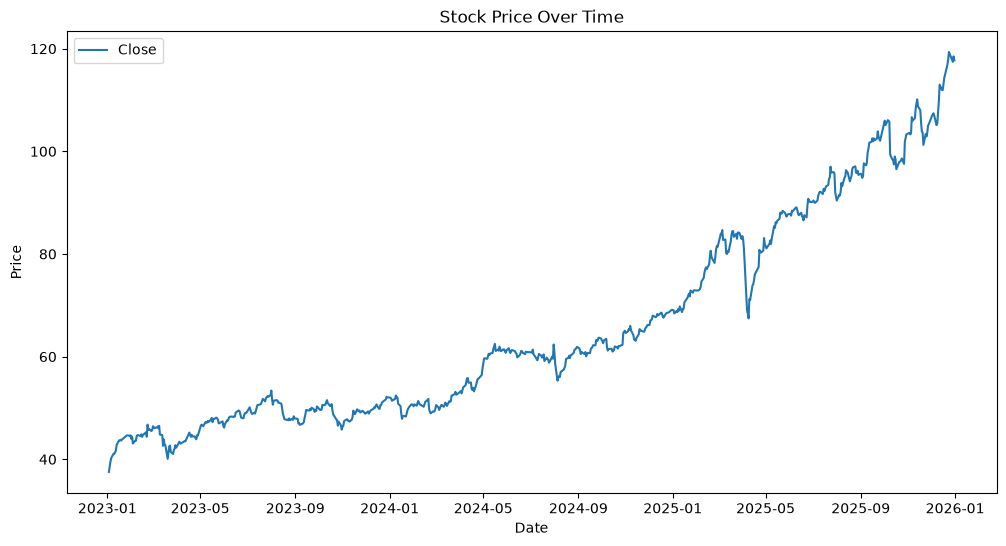

In [28]:
# To visual data 
plt.figure(figsize=(12, 6))
plt.plot(df['Close'], label='Close')
plt.title("Stock Price Over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

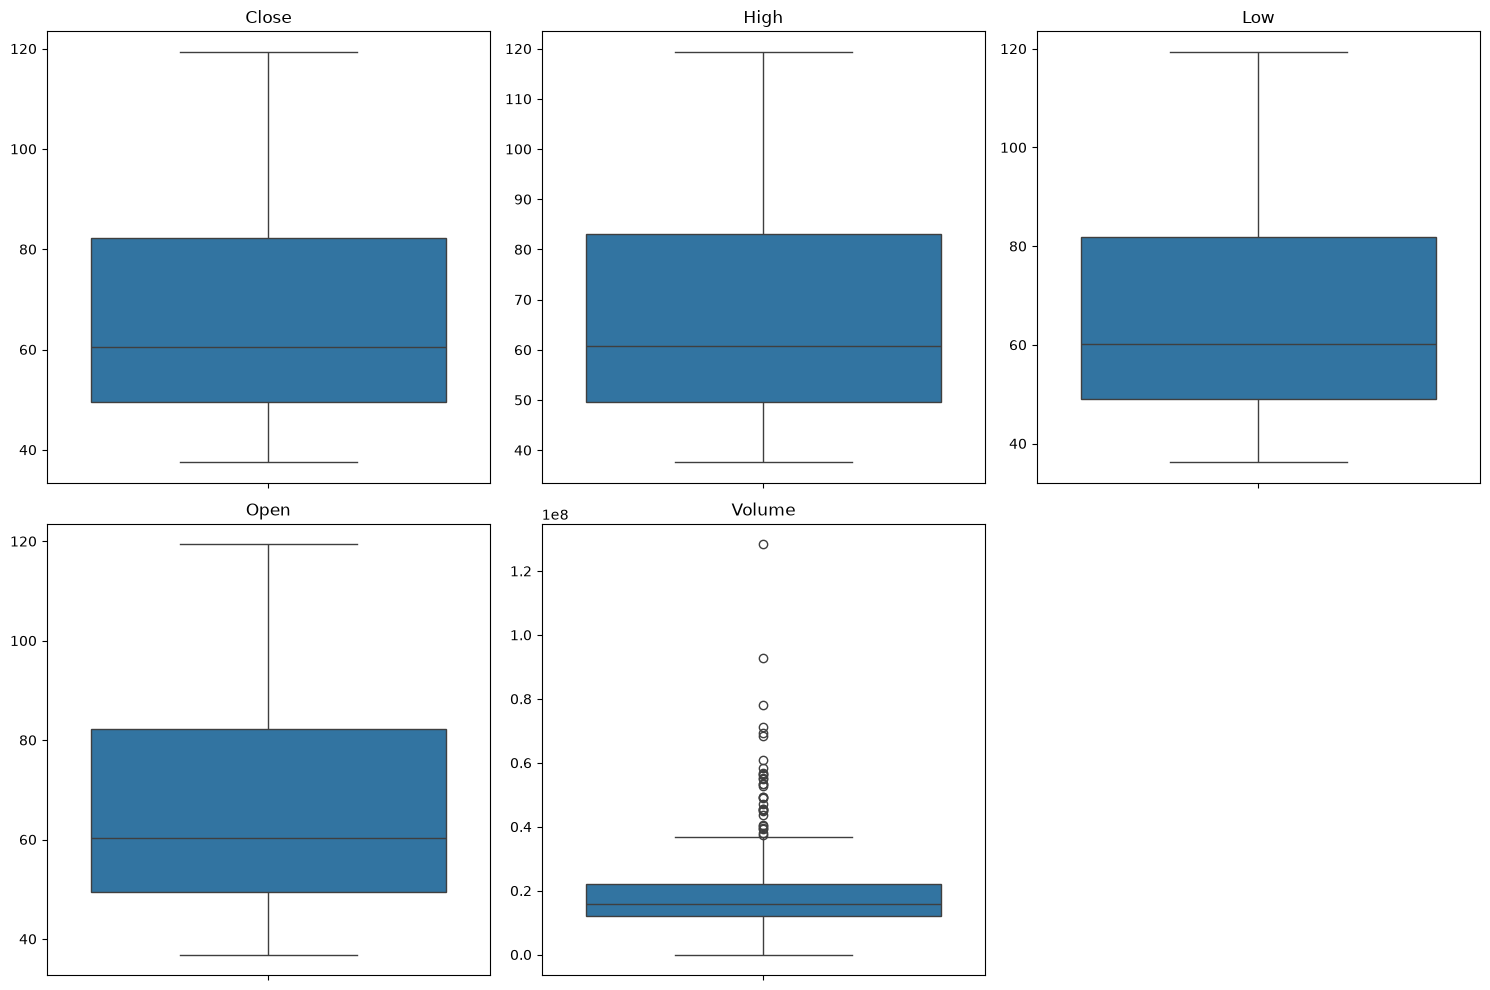

In [29]:
# To study data outliers and variations

#import math
#import matplotlib.pyplot as plt
#import seaborn as sns

num_cols = 3
num_features = len(df.columns)
num_rows = math.ceil(num_features / num_cols)

fig = plt.figure(figsize=(15, num_rows * 5))

for i, x in enumerate(df.columns, start=1):
    plt.subplot(num_rows, num_cols, i)
    ax = sns.boxplot(df[x])
    ax.set(xlabel=None)
    plt.title(str(x), loc='center')
    plt.xlabel(None)
    plt.ylabel(None)

plt.tight_layout()
plt.show()

Box plots apply to identify outliers; may identify anomalous trading days or incorrect data points

In [30]:
# Data pre-processing
df.isnull().sum()

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [31]:
# This is preserve as for handling missing values, if applicable
df.bfill()

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,37.538029,37.615108,36.227666,36.844306,17994602
2023-01-04,38.540062,38.540062,38.039040,38.116122,20526070
2023-01-05,39.503567,39.619188,39.118166,39.310866,29598352
2023-01-06,40.235828,40.582690,40.043128,40.428529,30945589
2023-01-09,41.083702,41.160784,40.698301,40.968084,25217005
...,...,...,...,...,...
2025-12-23,117.824440,117.920779,117.150052,117.439077,10892666
2025-12-24,119.365891,119.365891,119.365891,119.365891,0
2025-12-29,117.439072,119.173196,117.053708,119.173196,13132355


In [32]:
# Calculate moving averages and daily returns

df['20-day MA'] = df['Close'].rolling(window=20).mean()
df['50-day MA'] = df['Close'].rolling(window=50).mean()
df['Daily Return'] = df['Close'].pct_change()

In [33]:
# To check NaN
df[df.isna().values==True].drop_duplicates()

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-01-03,37.538029,37.615108,36.227666,36.844306,17994602,NaN,NaN,NaN
2023-01-04,38.540062,38.540062,38.039040,38.116122,20526070,NaN,NaN,0.026694
2023-01-05,39.503567,39.619188,39.118166,39.310866,29598352,NaN,NaN,0.025000
2023-01-06,40.235828,40.582690,40.043128,40.428529,30945589,NaN,NaN,0.018537
2023-01-09,41.083702,41.160784,40.698301,40.968084,25217005,NaN,NaN,0.021073
2023-01-10,41.083702,41.122242,40.775383,40.968084,15923846,NaN,NaN,0.000000
2023-01-11,41.353485,41.546185,41.083703,41.237864,19895897,NaN,NaN,0.006567
2023-01-12,41.700344,41.700344,41.353486,41.469104,18594710,NaN,NaN,0.008388
2023-01-13,42.779465,42.779465,42.355525,42.394064,31176673,NaN,NaN,0.025878


In [34]:
df = df.dropna()   # Drop all NaN
df

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-03-16,42.828857,42.948045,42.352097,42.431558,26622653,45.351558,43.985589,-0.023551
2023-03-17,42.749393,42.908314,42.193174,42.908314,19300748,45.245996,44.089816,-0.001855
2023-03-20,40.087486,41.954791,39.491538,41.875333,56886469,44.986141,44.120765,-0.062268
2023-03-21,41.239655,41.358842,40.723164,41.319113,36238398,44.828217,44.155487,0.028741
2023-03-22,42.511013,42.908312,41.994523,42.034255,29346962,44.616312,44.200990,0.030829
...,...,...,...,...,...,...,...,...
2025-12-23,117.824440,117.920779,117.150052,117.439077,10892666,109.548791,105.471437,0.008244
2025-12-24,119.365891,119.365891,119.365891,119.365891,0,110.333966,105.909448,0.013083
2025-12-29,117.439072,119.173196,117.053708,119.173196,13132355,110.955362,106.278315,-0.016142


In [35]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 686 entries, 2023-03-16 to 2025-12-31
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Close         686 non-null    float64
 1   High          686 non-null    float64
 2   Low           686 non-null    float64
 3   Open          686 non-null    float64
 4   Volume        686 non-null    int64  
 5   20-day MA     686 non-null    float64
 6   50-day MA     686 non-null    float64
 7   Daily Return  686 non-null    float64
dtypes: float64(7), int64(1)
memory usage: 48.2 KB


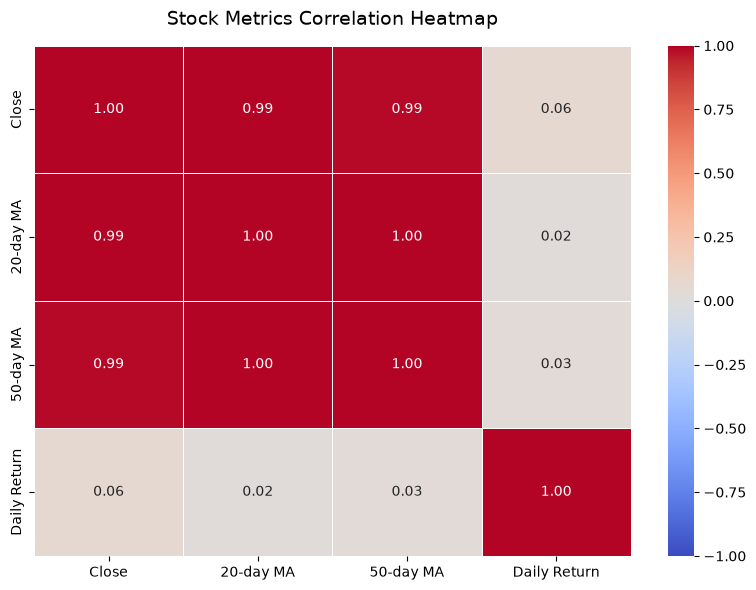

In [36]:
#import matplotlib.pyplot as plt
#import seaborn as sns

#
correlation_matrix = df[["Close", "20-day MA", "50-day MA", "Daily Return"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,       # Shows the correlation coefficients in the squares 
    cmap="coolwarm",  # Diverging colour palette (blue = negative, red = positive)
    vmin=-1,
    vmax=1,           # Sets the limits of the colour bar (-1 to 1)
    center=0,         # Centers the colour scale at 0 (neutral)
    fmt=".2f",        # Rounds numbers to 2 decimal places
    linewidths=0.5,   # Adds lines between the squares
)

#
plt.title("Stock Metrics Correlation Heatmap", fontsize=14, pad=15)
plt.tight_layout()
plt.show()


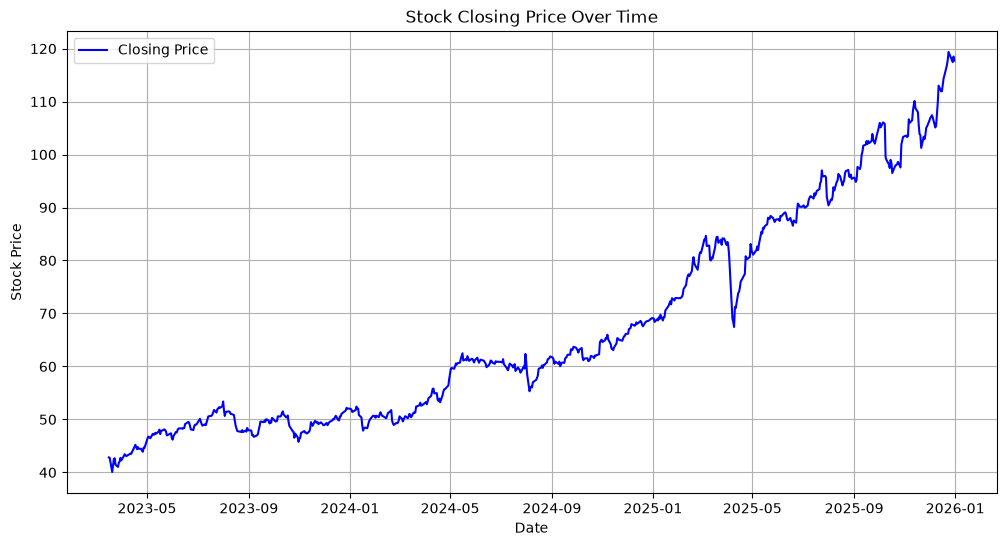

In [37]:
# EDA to explore trends and patterns

plt.figure(figsize=(12,6))
plt.xlabel("Date")  
plt.ylabel("Stock Price")  
plt.title("Stock Closing Price Over Time")  
plt.plot(df['Close'], label="Closing Price", color="blue")
#plt.plot(df['Date'], df['Close'], label="Closing Price", color="blue")  
plt.grid(True)
plt.legend()  
plt.show()

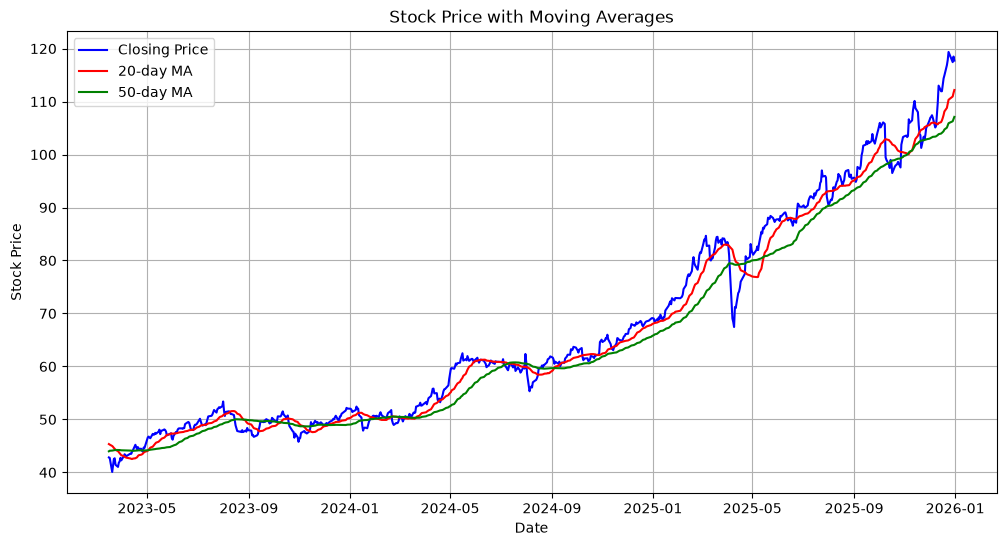

In [38]:
# To smoothen short-term fluctuations with moving averages

plt.figure(figsize=(12,6))
plt.xlabel("Date")  
plt.ylabel("Stock Price")  
plt.title("Stock Price with Moving Averages")
plt.plot(df['Close'], label="Closing Price", color="blue")
plt.plot(df['20-day MA'], label="20-day MA", color="red")
plt.plot(df['50-day MA'], label="50-day MA", color="green")
#plt.plot(df['Date'], df['Close'], label="Closing Price", color="blue")  
plt.grid(True)
plt.legend()  
plt.show()


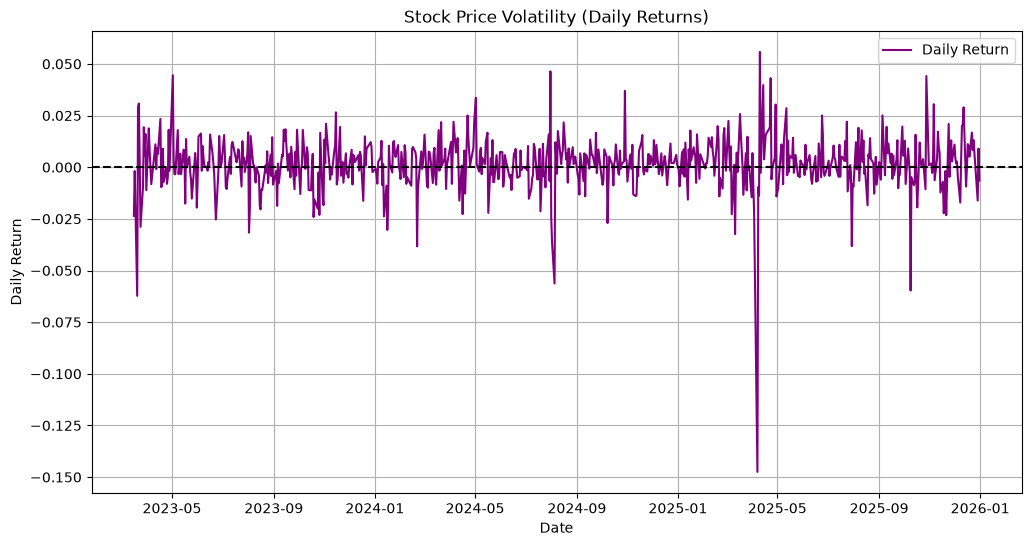

In [39]:
# To analyse Volatility

plt.figure(figsize=(12, 6))
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.title("Stock Price Volatility (Daily Returns)")
plt.plot(df['Daily Return'], label="Daily Return", color='purple')
plt.axhline(y=0, color='black', linestyle='--')
plt.grid(True)
plt.legend()
plt.show()

In [40]:
# To check basic statistical details
df.describe()

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
count,686.000000,686.000000,686.000000,686.000000,6.860000e+02,686.000000,686.000000,686.000000
mean,67.284678,67.664480,66.792339,67.197819,1.844928e+07,66.321335,64.957983,0.001531
std,19.946559,20.044710,19.794287,19.906413,1.087692e+07,19.191343,18.341303,0.013356
min,40.087486,41.358842,39.491538,41.279379,0.000000e+00,42.524916,43.985589,-0.147503
25%,50.116860,50.361956,49.849098,50.051711,1.203324e+07,50.049082,49.653523,-0.004454
50%,61.031166,61.400248,60.672680,60.928719,1.550120e+07,60.746170,59.862560,0.001721
75%,83.697142,83.908801,83.179645,83.438459,2.166406e+07,81.432067,79.596350,0.008094
max,119.365891,119.365891,119.365891,119.365891,1.283405e+08,112.178886,107.104240,0.055788


In [41]:
# For normailized Data

# from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))  
scaled_data = scaler.fit_transform(df['Daily Return'].values.reshape(-1,1))

In [42]:
# ADF Test : p-value < 0.05 for stationary data

#from statsmodels.tsa.stattools import adfuller

close_series = df['Daily Return']
def check_stationarity(series):
    result = adfuller(series.dropna())  # Drop NaN values if any
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    if result[1] < 0.05:
        print("The series is stationary.")
    else:
        print("The series is not stationary.")

check_stationarity(close_series)

ADF Statistic: -15.982773088406999
p-value: 6.806313729202358e-29
The series is stationary.


For this study, we will focus on the adj closing price with Daily Return

#... To export initial data sets

In [43]:
df.isnull().sum()

Close           0
High            0
Low             0
Open            0
Volume          0
20-day MA       0
50-day MA       0
Daily Return    0
dtype: int64

In [44]:
df[df.isna().values==True].drop_duplicates()

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,


In [45]:
# Prepare for initial set of data for analysis
dftune = df
dftune = dftune.rename(columns={"Daily Return": "Adj Close"})


In [58]:
dftune [["Adj Close"]].to_csv("0700.HK260102.csv")


In [85]:
dftune [["Adj Close"]].to_csv("0005.HK260102.csv")


In [164]:
dftune [["Adj Close"]].to_csv("^hsi260102.csv")


In [188]:
dftune [["Adj Close"]].to_csv("^GSPC260102.csv")


In [29]:
dftune [["Adj Close"]].to_csv("AAPL260102.csv")


...